# Module 43 — Object Segmentation

## 5. Segmentation Metrics

**Must Know — Evaluation**

---

Now we know how segmentation masks are created and represented. The next question is:

**How do we measure whether a segmentation model is predicting accurate masks?**

Suppose we train a U-Net model to identify a tumour in an MRI scan.

The model predicts a segmentation mask, but how do we know whether its predicted tumour region matches the actual tumour?

We compare two masks:

1. **Ground Truth Mask:** The correct mask created by human annotation.
2. **Predicted Mask:** The mask generated by our trained model.


*Medical image segmentation example.*

**Original reference:**

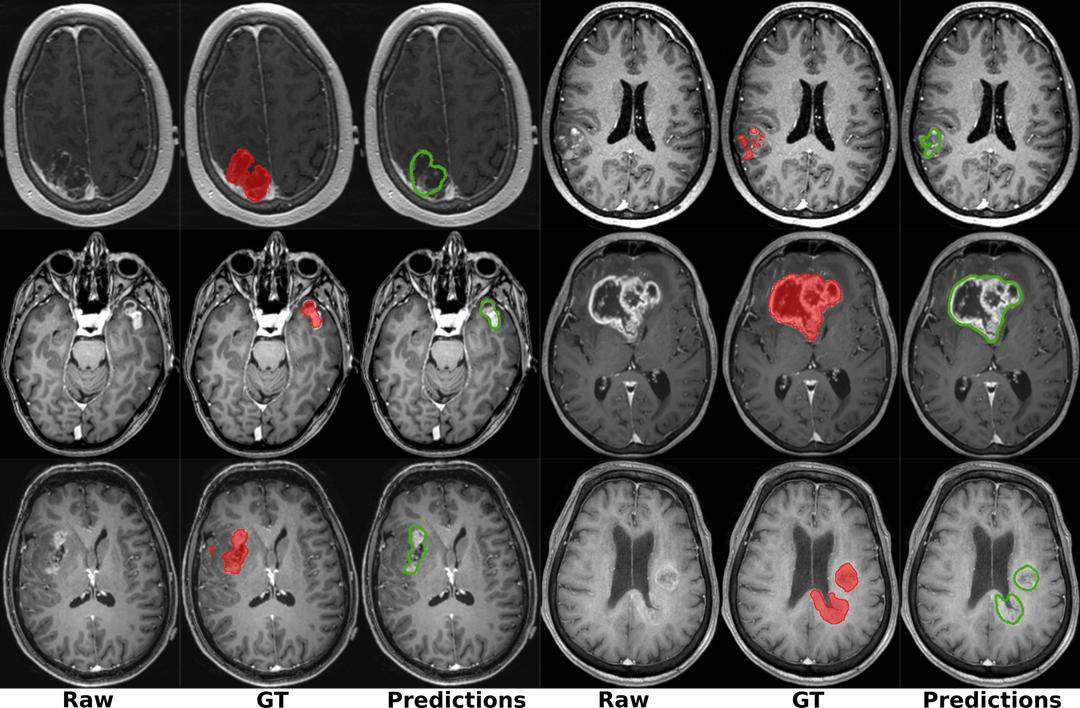

We use four important evaluation metrics:

1. Intersection over Union (IoU)
2. Dice Score
3. Pixel Accuracy
4. Mean IoU (mIoU)

### 5.1 Intersection over Union (IoU)

IoU measures how much the predicted segmentation overlaps with the ground-truth segmentation.

It is also called the **Jaccard Index**.

Imagine:

- Ground truth identifies the actual tumour region.
- The model predicts a tumour region.
- Some pixels overlap, while others do not.

IoU measures the overlap relative to the total area covered by either mask.

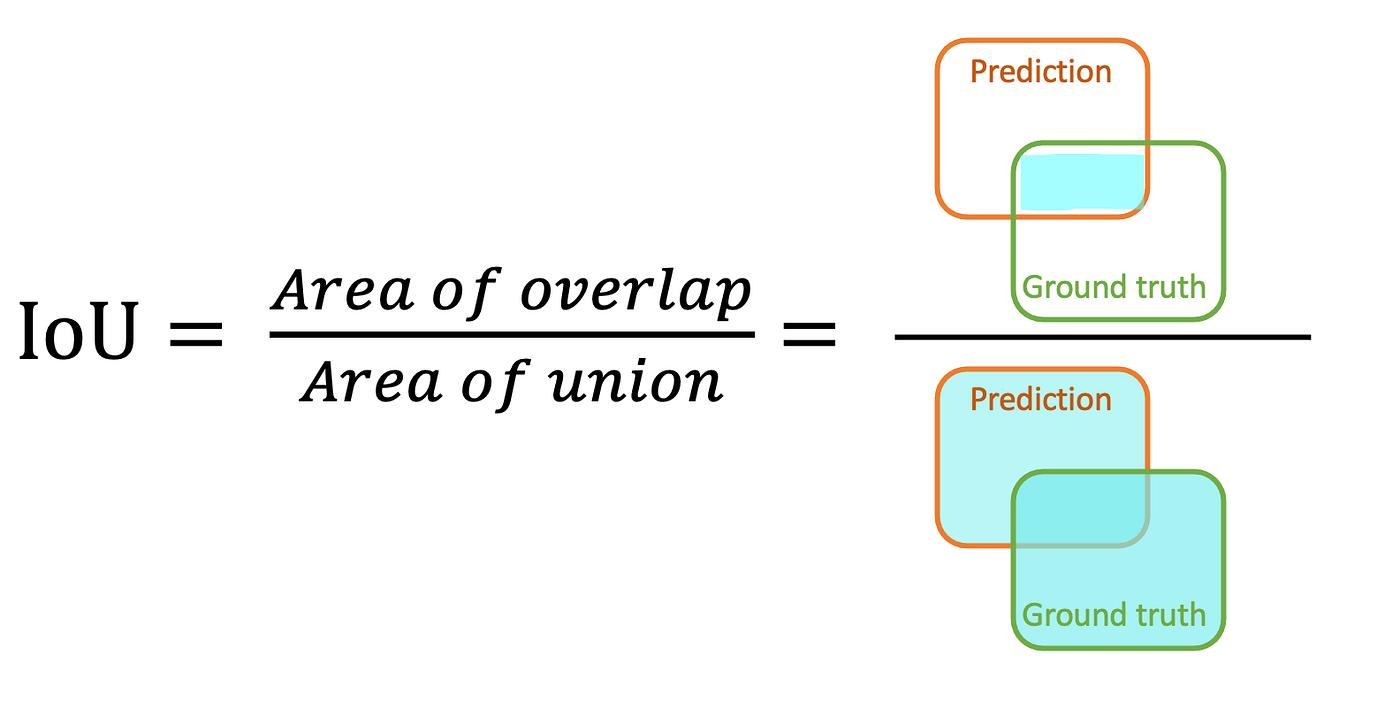

*Source: [Intersection over Union — Wikipedia](https://en.wikipedia.org/wiki/Jaccard_index)*

**Original reference:**

- [Understanding Evaluation Metrics in Medical Image Segmentation — Medium](https://images.openai.com/static-rsc-4/gDauDhycphSUMuPt0lfpNuKqMackZksu23d0oYaMZI7JBtmM0YXvtIJfqwrT0AWiaHFkE46PHjdcjELuCFBBB6u8gYyvbGzKWJJID62fFVCQu3MqKqJa_zT_Kh8Lbq95dHc8bYv9ykLRtmscYO9oYWmBMn6wofSNGBRZtRvKiDc?purpose=inline)
- [medium.com](https://medium.com/mastering-data-science/understanding-evaluation-metrics-in-medical-image-segmentation-d289a373a3f?utm_source=chatgpt.com)

**Mathematical formula:**

$$
IoU = \frac{|A \cap B|}{|A \cup B|}
$$

Where:

- \\(A\\) = Ground-truth mask.
- \\(B\\) = Predicted mask.
- \\(A \cap B\\) = Intersection (overlapping pixels).
- \\(A \cup B\\) = Union (all pixels belonging to either mask).

**Example:**

Suppose:

- Ground-truth region = 100 pixels.
- Predicted region = 80 pixels.
- Overlapping region = 60 pixels.

Then:

$$
IoU = \frac{60}{100+80-60}
$$

$$
IoU = \frac{60}{120}=0.5
$$

<badge color="success">IoU = 0.50</badge>

This means the predicted region overlaps 50% of the combined ground-truth and predicted region.

**Interpretation:**

| IoU | Interpretation |
|---:|---|
| 0 | No overlap |
| 0.25 | Low overlap |
| 0.50 | Moderate overlap |
| 0.75 | Good overlap |
| 1.00 | Perfect overlap |

These are illustrative interpretations, not universal quality thresholds. Acceptable IoU depends on the application.

### 5.2 Dice Score

The Dice Score measures the similarity between the predicted mask and the ground-truth mask.

It is particularly common in medical image segmentation.

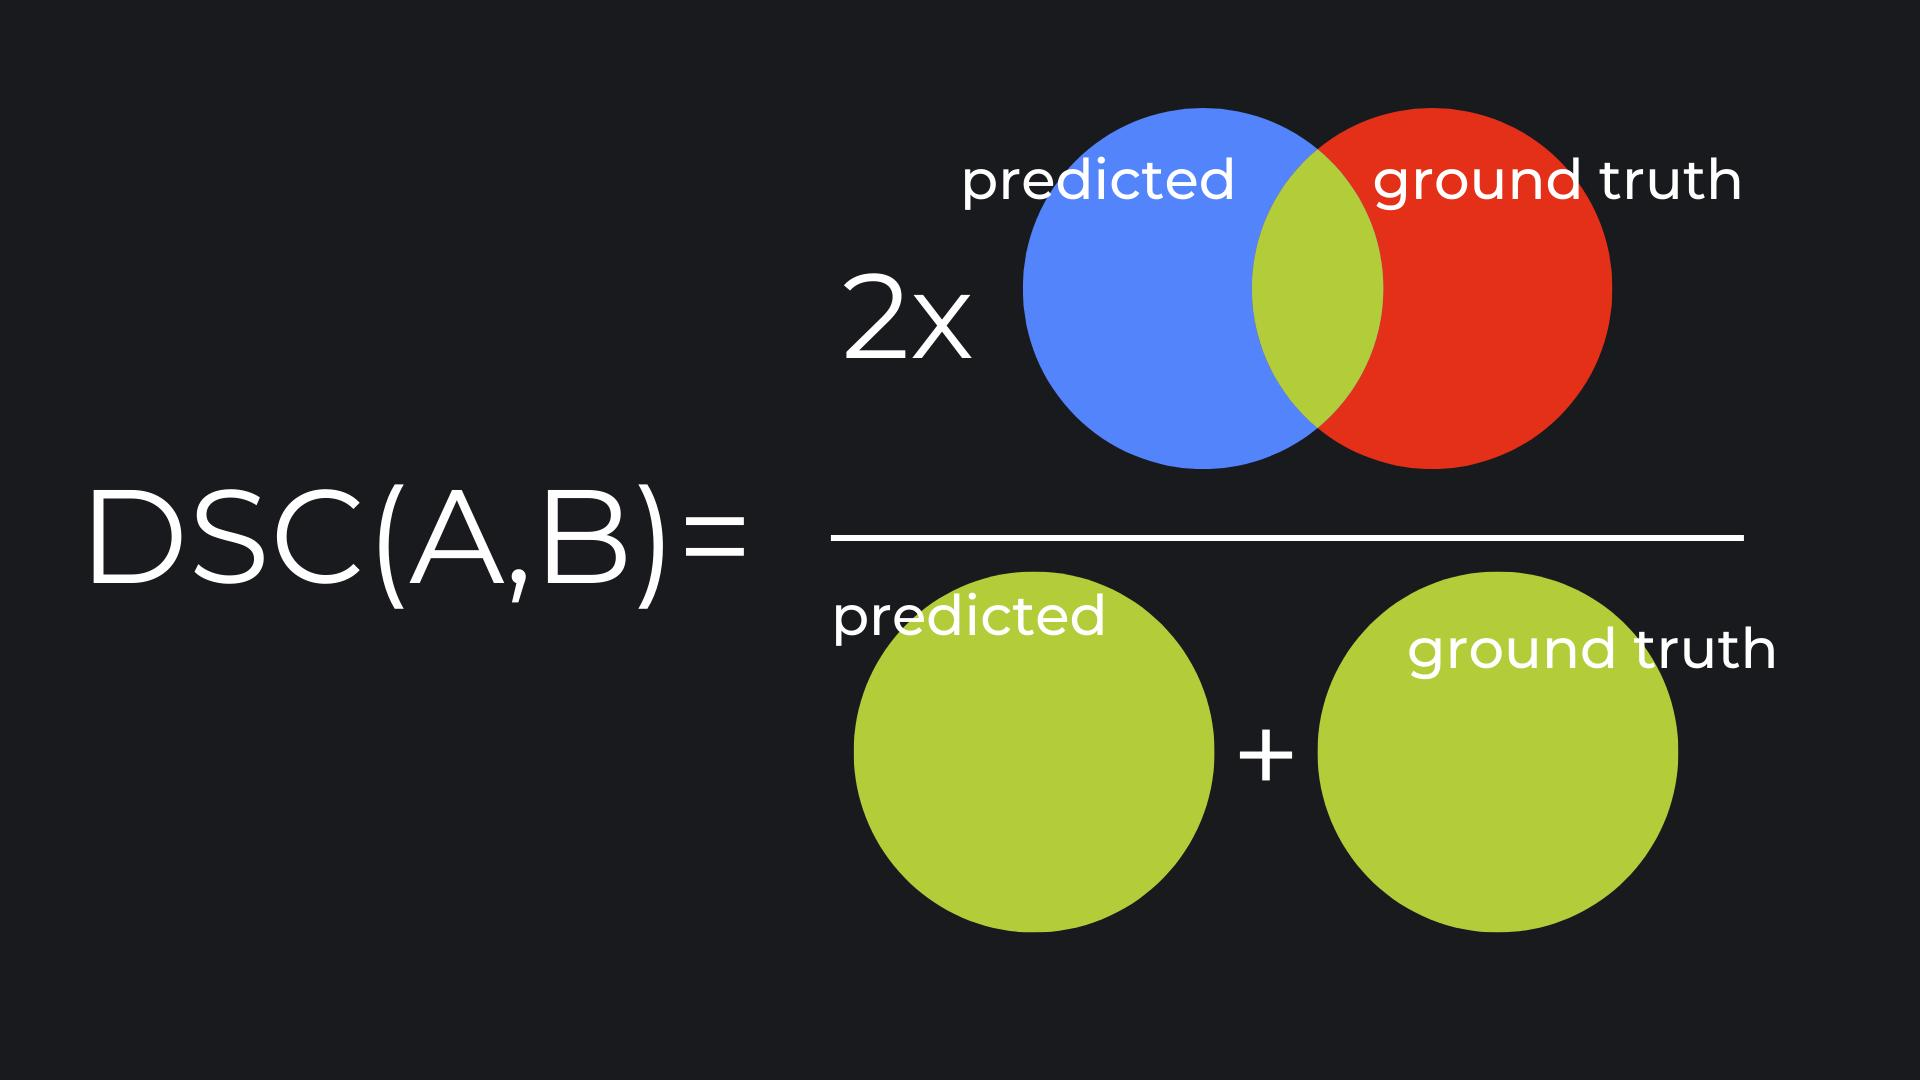

*Source: [Dice Similarity Coefficient](https://en.wikipedia.org/wiki/S%C3%B8rensen%E2%80%93Dice_coefficient)*

**Original reference:**

- [Dice Coefficient Python Segmentation — Clifford Bloss](https://images.openai.com/static-rsc-4/hnGYn7Kvh4fRvUEw9BwN6f-mXiqviZV4CSnabBkpN_2QUVMbZJKoXWceuKM0SgGuah9fPA4xENR_v0kGOXMC47j2JVs5wQgabWbR-5b1EoogShUGOzVmqT3Qvkfy0e-Qnr74-QVmG0Lp8DbOLjo8Ww3FCaJ6bq3wwkd6T-DUipw?purpose=inline)
- [storage.googleapis.com](https://storage.googleapis.com/dbhsnokwkgeqbe/dice-coefficient-python-segmentation.html?utm_source=chatgpt.com)

**Mathematical formula:**

$$
Dice = \frac{2|A \cap B|}{|A|+|B|}
$$

Where:

- \\(A\\) = Ground-truth mask.
- \\(B\\) = Predicted mask.
- \\(|A \cap B|\\) = Number of overlapping pixels.

Using our previous example:

- Ground truth = 100 pixels.
- Prediction = 80 pixels.
- Intersection = 60 pixels.

$$
Dice = \frac{2 \times 60}{100+80}
$$

$$
Dice = \frac{120}{180}
$$

$$
Dice = 0.667
$$

<badge color="success">Dice = 0.667</badge>

**Relationship between IoU and Dice**

These metrics are mathematically related:

$$
Dice = \frac{2IoU}{1+IoU}
$$

And:

$$
IoU = \frac{Dice}{2-Dice}
$$

This means both measure mask overlap, but Dice generally produces a higher numerical score for the same prediction.

| IoU | Dice |
|---:|---:|
| 0.25 | 0.40 |
| 0.50 | 0.667 |
| 0.75 | 0.857 |
| 1.00 | 1.00 |

**When is Dice useful?**

- Medical image segmentation.
- Tumour segmentation.
- Organ segmentation.
- Small foreground region segmentation.

### 5.3 Pixel Accuracy

Pixel Accuracy measures the percentage of correctly classified pixels out of all pixels in an image.

Unlike IoU and Dice, pixel accuracy considers both foreground and background classifications.

![Pixel classification confusion matrix illustrating TP, TN, FP and FN](https://upload.wikimedia.org/wikipedia/commons/2/26/Precisionrecall.svg)

*Source: [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall)*

**Original reference:**

- [How to Measure Model Performance in Computer Vision — Encord](https://images.openai.com/static-rsc-4/eF5_tpZ6A4thmPJpa-TVYOj1ar3_9TEPc0ab52oQLevAE8Hqt0vuDDv56enZ-R_ly9DXkxOK_IFERRdPs4sBMeaZa5lxSjaaB-b75U2J3mogi8PDdlX5qmsaJpUop5gpoYEjH31hwkcnf33e0xJbDJTBu-nNBabnbBtUs1YjEWM?purpose=inline)
- [encord.com](https://encord.com/blog/measure-model-performance-computer-vision/?utm_source=chatgpt.com)

Its formula is:

$$
Pixel\ Accuracy =
\frac{\text{Correctly classified pixels}}
{\text{Total pixels}}
$$

For binary segmentation, we can expand this using a confusion matrix:

| | Predicted foreground | Predicted background |
|---|---|---|
| Actual foreground | TP | FN |
| Actual background | FP | TN |

Where:

- TP = True Positive.
- TN = True Negative.
- FP = False Positive.
- FN = False Negative.

Therefore:

$$
PA = \frac{TP+TN}{TP+TN+FP+FN}
$$

**Example:**

Suppose an image contains 100 pixels.

| Classification | Pixels |
|---|---:|
| True Positive | 6 |
| True Negative | 86 |
| False Positive | 2 |
| False Negative | 6 |
| Total | 100 |

$$
PA = \frac{6+86}{100}
$$

$$
PA = 0.92 = 92\%
$$

<badge color="success">Pixel Accuracy = 92%</badge>

**Important limitation: Class Imbalance**

Imagine an image where:

- 95% of pixels are background.
- 5% of pixels contain a tumour.

A model that predicts every pixel as background can achieve 95% pixel accuracy while completely failing to identify the tumour.

This is why pixel accuracy alone is insufficient for many segmentation problems.

### 5.4 Mean Intersection over Union (mIoU)

So far, we have discussed IoU for an individual class.

But what happens when a segmentation model has multiple classes?

For example:

- Road
- Car
- Person
- Building
- Tree
- Sky

We calculate IoU separately for each class and then take their average.

This is called **Mean Intersection over Union (mIoU).**

![Semantic segmentation prediction showing multiple classes in an urban scene](https://www.researchgate.net/profile/Simon-Wenkel/publication/366048384/figure/fig1/AS:11431281103622254@1670277312842/Semantic-segmentation-examples-on-Cityscapes-dataset.png)

*Source: Cityscapes semantic segmentation examples.*

**Original reference:**

- [AI model speeds up high-resolution computer vision — EurekAlert!](https://images.openai.com/static-rsc-4/Td2LGiE46muWKFCeTsXEtEvvCCxttbUprlZOOIPXoSNdMqXzYEc0T16k_v3ZZIrvzouMMtHQIzUEbD0pbWmqLxh5ER2WEY8Zl-TniNv56bSSPuxpbAtgSSFUo9WZcrb74ER16yt5XSAauUhkbn8q4aDSEASeYPfVPg3rsAxjnHI?purpose=inline)
- [eurekalert.org](https://www.eurekalert.org/news-releases/1001258?utm_source=chatgpt.com)

**Formula:**

$$
mIoU = \frac{1}{C}\sum_{c=1}^{C} IoU_c
$$

Where:

- \\(C\\) = Number of classes included in the average.
- \\(IoU_c\\) = IoU of an individual class.

**Example:**

Suppose a model predicts four classes.

| Class | IoU |
|---|---:|
| Road | 0.90 |
| Car | 0.80 |
| Person | 0.60 |
| Building | 0.70 |

Then:

$$
mIoU = \frac{0.90+0.80+0.60+0.70}{4}
$$

$$
mIoU = \frac{3.00}{4}
$$

$$
\boxed{mIoU=0.75}
$$

<badge color="success">mIoU = 75%</badge>

**Why is mIoU important?**

It helps evaluate the model across multiple classes instead of allowing a dominant class, such as background or road, to hide poor performance on smaller classes.

**A practical detail:** The averaging convention matters. Some benchmarks exclude background or classes absent from the ground truth; always check the evaluation protocol.

### 5.5 Comparison of All Four Metrics

| Metric | What it measures | Best used for |
|---|---|---|
| IoU | Overlap between two masks | Segmentation quality |
| Dice | Similarity between two masks | Medical segmentation |
| Pixel Accuracy | Correctly classified pixels | Overall pixel classification |
| mIoU | Average IoU across classes | Multi-class segmentation |

**Important differences**

- **IoU vs Dice:** Both evaluate overlap, but use different mathematical formulas.
- **Pixel Accuracy vs IoU:** Pixel accuracy counts all correctly classified pixels, including background. IoU focuses on overlap for a class.
- **IoU vs mIoU:** IoU evaluates an individual class; mIoU averages class-wise IoU values.

### 5.6 Practical Industry Evaluation

Different applications prioritize different metrics:

| Application | Important metrics |
|---|---|
| Medical tumour segmentation | Dice, IoU |
| Autonomous driving | mIoU, per-class IoU |
| Agricultural segmentation | IoU, Dice |
| Industrial defect segmentation | IoU, Dice, Precision, Recall |

One important industry practice: never evaluate a segmentation model using only one metric. Combine quantitative metrics with visual inspection of predicted masks and failure cases.

## What You Should Remember 🧠

1. IoU measures intersection divided by union.
2. Dice measures twice the intersection divided by the sum of mask areas.
3. Dice and IoU are mathematically related.
4. Pixel Accuracy measures the percentage of correctly classified pixels.
5. Pixel Accuracy can be misleading when classes are imbalanced.
6. mIoU averages IoU across multiple classes.
7. Higher scores generally indicate better segmentation, but the evaluation protocol matters.

---